In [1]:
import pandas as pd
import numpy as np


In [3]:
df = pd.read_csv("C:\\Users\\user\\Desktop\\Colab Notebooks\\Homework2\\Homework2.csv")
df.head(5)

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
0,2006,Europe,Gasoline,Front-wheel drive,4,2180,6,243.0,3870,NaN,31.9
1,2008,Europe,Diesel,Front-wheel drive,4,2390,6,272.0,4210,NaN,31.3
2,1996,Asia,Gasoline,Front-wheel drive,5,2320,6,267.0,4240,17.3,27.5
3,1989,Europe,Gasoline,Front-wheel drive,4,2130,6,258.0,4490,18.7,28.5
4,1994,USA,Diesel,Front-wheel drive,3,2580,7,304.0,4510,17.5,31.0


# Data preparation

In [4]:
df.columns.str.lower()

Index(['model_year', 'origin', 'fuel_type', 'drivetrain', 'num_doors',
       'engine_displacement', 'num_cylinders', 'horsepower', 'vehicle_weight',
       'acceleration', 'fuel_efficiency_mpg'],
      dtype='str')

In [5]:
df.columns = df.columns.str.lower().str.replace(' ', '_')

In [6]:
df.tail(5)

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
9995,2005,USA,Gasoline,All-wheel drive,4,2470,6,271.0,4690,18.9,27.4
9996,1993,Asia,Gasoline,All-wheel drive,2,2300,6,244.0,4370,19.0,30.0
9997,2014,USA,Gasoline,All-wheel drive,3,2480,6,267.0,4590,18.4,28.1
9998,2004,USA,Hybrid,Rear-wheel drive,5,2180,6,270.0,4450,20.9,32.2
9999,2011,USA,Diesel,Front-wheel drive,4,2380,6,295.0,4370,17.6,30.2


In [7]:
df.dtypes

model_year               int64
origin                     str
fuel_type                  str
drivetrain                 str
num_doors                int64
engine_displacement      int64
num_cylinders            int64
horsepower             float64
vehicle_weight           int64
acceleration           float64
fuel_efficiency_mpg    float64
dtype: object

In [8]:
strings = list(df.dtypes[df.dtypes == 'object'].index)
strings

[]

In [9]:
df.isnull().sum()

model_year               0
origin                   0
fuel_type                0
drivetrain               0
num_doors                0
engine_displacement      0
num_cylinders            0
horsepower             877
vehicle_weight           0
acceleration           264
fuel_efficiency_mpg      0
dtype: int64

In [11]:
df.horsepower.median()


np.float64(254.0)

In [22]:
df.acceleration.median()

np.float64(18.9)

In [19]:
df['horsepower'].isna().mean() * 10

np.float64(0.877)

In [25]:
df['horsepower'] = df['horsepower'].fillna(
    df['horsepower'].mean()
)

In [26]:
df.isnull().sum()

model_year               0
origin                   0
fuel_type                0
drivetrain               0
num_doors                0
engine_displacement      0
num_cylinders            0
horsepower               0
vehicle_weight           0
acceleration           264
fuel_efficiency_mpg      0
dtype: int64

In [27]:
df['acceleration'] = df['acceleration'].fillna(
    df['acceleration'].mean()
)

In [28]:
df.isnull().sum()

model_year             0
origin                 0
fuel_type              0
drivetrain             0
num_doors              0
engine_displacement    0
num_cylinders          0
horsepower             0
vehicle_weight         0
acceleration           0
fuel_efficiency_mpg    0
dtype: int64

# EDA

In [29]:
for col in df.columns:
    print(col)
    print(df[col].unique()[:5])
    print(df[col].nunique())
    print()

model_year
[2006 2008 1996 1989 1994]
50

origin
<ArrowStringArray>
['Europe', 'Asia', 'USA']
Length: 3, dtype: str
3

fuel_type
<ArrowStringArray>
['Gasoline', 'Diesel', 'Hybrid']
Length: 3, dtype: str
3

drivetrain
<ArrowStringArray>
['Front-wheel drive', 'Rear-wheel drive', 'All-wheel drive']
Length: 3, dtype: str
3

num_doors
[4 5 3 2]
4

engine_displacement
[2180 2390 2320 2130 2580]
127

num_cylinders
[6 7 5 8 4]
5

horsepower
[243. 272. 267. 258. 304.]
154

vehicle_weight
[3870 4210 4240 4490 4510]
176

acceleration
[18.88804437 17.3        18.7        17.5        18.8       ]
94

fuel_efficiency_mpg
[31.9 31.3 27.5 28.5 31. ]
188



# Distribution of price

In [30]:
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

<Axes: xlabel='fuel_efficiency_mpg', ylabel='Count'>

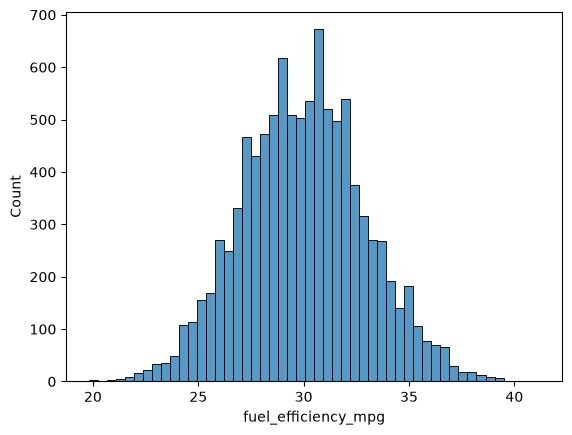

In [32]:
sns.histplot(df.fuel_efficiency_mpg, bins=50)

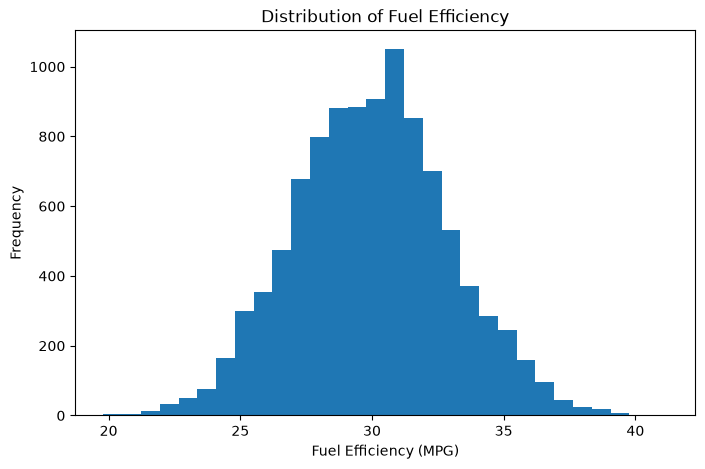

In [33]:
plt.figure(figsize=(8, 5))

plt.hist(df['fuel_efficiency_mpg'], bins=30)

plt.xlabel('Fuel Efficiency (MPG)')
plt.ylabel('Frequency')
plt.title('Distribution of Fuel Efficiency')

plt.show()

C:\Users\user\AppData\Local\Temp\ipykernel_12900\2103081152.py:3: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df['fuel_efficiency_mpg'].dropna(), vert=False)


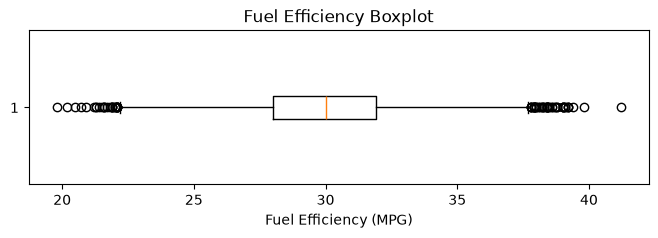

In [34]:
plt.figure(figsize=(8, 2))

plt.boxplot(df['fuel_efficiency_mpg'].dropna(), vert=False)

plt.xlabel('Fuel Efficiency (MPG)')
plt.title('Fuel Efficiency Boxplot')

plt.show()

In [35]:
df['fuel_efficiency_mpg'].describe()


count    10000.000000
mean        29.997700
std          2.930245
min         19.800000
25%         28.000000
50%         30.000000
75%         31.900000
max         41.200000
Name: fuel_efficiency_mpg, dtype: float64